# 07 · EDA: the main findings
What the data changes about how we train and test. It runs on the clean dataset in a few minutes on CPU. The much longer analysis, with embeddings and photo quality, is Manas's notebook, `Group 5 - 2026T3 - DSAI Lab.ipynb`.

In [1]:
import json
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

DATA_DIR = Path(kagglehub.dataset_download("puneetbajajiitm/serpentguard-indian-snakes-clean"))
MASKS_DIR = Path(kagglehub.dataset_download("puneetbajajiitm/serpentguard-sam-masks"))
OUT_DIR = Path("/kaggle/working/figures")
OUT_DIR.mkdir(parents=True, exist_ok=True)

SPLITS = ["train", "val", "test", "test_extra"]
INPUT_SIZES = (224, 320, 384)
SMALL_SNAKE_PX = 64
COLOUR_PHOTOS_PER_CLASS = 30
DARK_BELOW, BRIGHT_ABOVE = 60, 200  # the exposure thresholds in notebook 06
IMAGENET_MEAN = (0.485, 0.456, 0.406)
BLUE, ORANGE, GREY, MUTED, GRID = "#2a78d6", "#eb6834", "#b8bcc2", "#5b6168", "#e6e7e9"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRID,
                     "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlelocation": "left",
                     "axes.titlesize": 12, "axes.axisbelow": True, "axes.grid": True, "grid.color": GRID})

meta = pd.read_csv(DATA_DIR / "metadata.csv", dtype={"observer_id": str, "obs_id": str}, low_memory=False)
classes = pd.read_csv(DATA_DIR / "classes.csv")
report = json.loads((DATA_DIR / "processing_report.json").read_text())
masks = pd.read_csv(MASKS_DIR / "mask_stats.csv", low_memory=False)
masks = masks[masks["path"].isin(meta.loc[meta["split"] == "train", "path"])]
meta["listed"] = meta["who_category"].astype(str) != "not_listed"
meta["portrait"] = meta["height"] > meta["width"] * 1.02


def finish(figure, name):
    figure.tight_layout()
    figure.savefig(OUT_DIR / f"{name}.png", dpi=170, bbox_inches="tight", facecolor="white")
    plt.show()


def label_bars(axis, values):
    for y, value in enumerate(values):
        axis.annotate(f"{value:,}", (value, y), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)

## 1. Classes are very uneven
The largest class has 12,038 photos and the smallest 22, a 547× gap, and 13 classes hold half the photos. Accuracy would mostly reflect those 13, so we report macro-F1 and per-class recall, and balance training in notebook 06.

121,566 photos, 184 classes, {'tier2': 128, 'tier1': 56}, 97 species in unknown_pool
Largest Indotyphlops braminus 12,038; smallest 22; median 178; ratio 547x
13 classes hold half the photos; effective classes 32.6
1000+ photos: 32 classes, 89,016 photos (73.7%)
500 to 999 photos: 20 classes, 14,528 photos (12.0%)
300 to 499 photos: 14 classes, 5,165 photos (4.3%)
100 to 299 photos: 45 classes, 8,352 photos (6.9%)
20 to 99 photos: 73 classes, 3,690 photos (3.1%)
At least 500: 52 | at least 300: 66 | under 100: 73


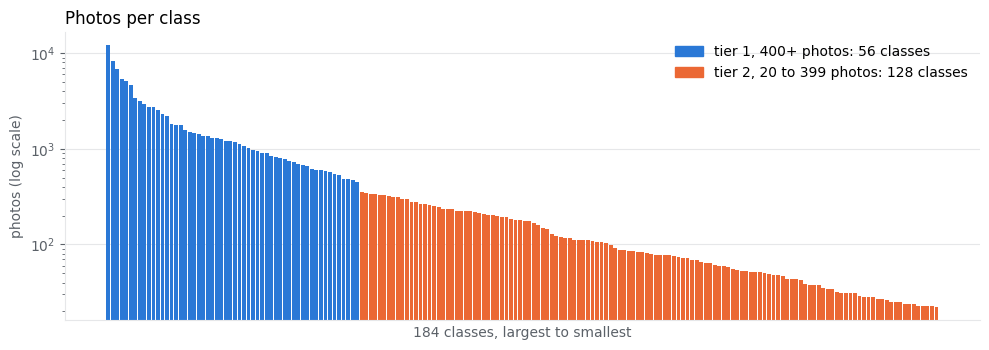

In [2]:
ranked = classes.sort_values("total", ascending=False)
share = ranked["total"] / ranked["total"].sum()
print(f"{len(meta):,} photos, {len(ranked)} classes, {ranked['tier'].value_counts().to_dict()}, {meta[meta['split'] == 'unknown_pool']['species'].nunique()} species in unknown_pool")
print(f"Largest {ranked['species'].iloc[0]} {ranked['total'].iloc[0]:,}; smallest {ranked['total'].iloc[-1]}; median {ranked['total'].median():.0f}; ratio {ranked['total'].iloc[0] / ranked['total'].iloc[-1]:.0f}x")
print(f"{(share.cumsum() < 0.5).sum() + 1} classes hold half the photos; effective classes {1 / (share ** 2).sum():.1f}")
for low, high in [(1000, None), (500, 999), (300, 499), (100, 299), (20, 99)]:
    group = ranked[(ranked["total"] >= low) & (ranked["total"] <= (high or ranked["total"].max()))]
    print(f"{low}{'+' if high is None else f' to {high}'} photos: {len(group)} classes, {group['total'].sum():,} photos ({group['total'].sum() / ranked['total'].sum():.1%})")
print("At least 500:", (ranked["total"] >= 500).sum(), "| at least 300:", (ranked["total"] >= 300).sum(), "| under 100:", (ranked["total"] < 100).sum())

figure, axis = plt.subplots(figsize=(10, 3.6))
axis.bar(range(len(ranked)), ranked["total"], color=ranked["tier"].map({"tier1": BLUE, "tier2": ORANGE}), width=0.85)
axis.set(yscale="log", xticks=[], ylabel="photos (log scale)", xlabel=f"{len(ranked)} classes, largest to smallest", title="Photos per class")
axis.grid(False, axis="x")
tiers = ranked["tier"].value_counts()
axis.legend([plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=ORANGE)],
            [f"tier 1, 400+ photos: {tiers['tier1']} classes", f"tier 2, 20 to 399 photos: {tiers['tier2']} classes"], frameon=False)
finish(figure, "photos_per_class")

## 2. Licences decide what stays
Taking out all-rights-reserved and no-derivatives photos removes 59,752 photos, about a third. What's left is CC0, CC BY, CC BY-SA, CC BY-NC or CC BY-NC-SA, which allow this non-commercial course project with credit.

                       kept  removed
cc-by-nd                  0      111
cc-by-sa               1185        0
cc0                    1471        0
cc-by-nc-sa            2628        0
cc-by-nc-nd               0     2902
cc-by                 14961        0
all-rights-reserved       0    56739
cc-by-nc             101321        0


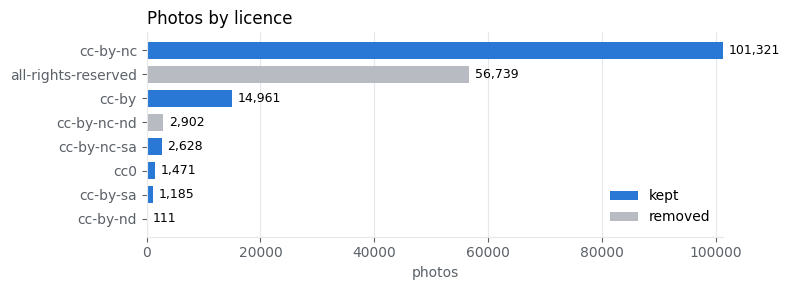

In [3]:
licences = pd.DataFrame({"kept": meta["license"].value_counts(), "removed": pd.Series(report["removed_by_licence"])}).fillna(0).astype(int)
licences = licences.loc[licences.sum(axis=1).sort_values().index]
print(licences.to_string())

figure, axis = plt.subplots(figsize=(8, 3))
axis.barh(licences.index, licences["kept"], color=BLUE, height=0.7, label="kept")
axis.barh(licences.index, licences["removed"], left=licences["kept"], color=GREY, height=0.7, label="removed")
label_bars(axis, licences.sum(axis=1))
axis.set(xlabel="photos", title="Photos by licence")
axis.grid(False, axis="y")
axis.legend(frameon=False, loc="lower right")
finish(figure, "photos_by_licence")

## 3. Test doesn't look like train
Only 37.4% of training photos are from India, but all of test is. In train, 77.8% of Category 1 photos are Indian against 33.0% of not-listed photos, so a model could learn "Indian scene means dangerous". That hint can't help on an all-Indian test set, so we also score Indian validation photos separately.

              photos  photographers  classes  in_india  india_pct  who_listed_pct  portrait_pct
split                                                                                          
test            5144            460      148      5144      100.0            27.1          60.0
test_extra     13389           1894      162      1965       14.7             9.2          35.0
train          85067          11272      184     31857       37.4            12.9          39.3
unknown_pool     815            255       97       670       82.2             2.3          30.4
val            17151           2249      176      6367       37.1            12.4          39.3

Share of training photos taken in India, by WHO category:
who_category
1             77.8
2             53.4
not_listed    33.0


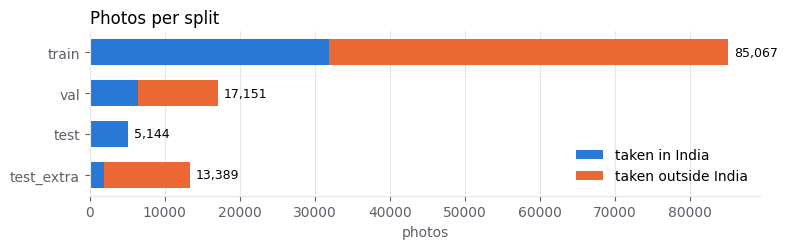

In [4]:
by_split = meta.groupby("split").agg(photos=("path", "size"), photographers=("observer_id", "nunique"), classes=("species", "nunique"), in_india=("in_india", "sum"),
                                     india_pct=("in_india", "mean"), who_listed_pct=("listed", "mean"), portrait_pct=("portrait", "mean"))
by_split[["india_pct", "who_listed_pct", "portrait_pct"]] = (by_split[["india_pct", "who_listed_pct", "portrait_pct"]] * 100).round(1)
print(by_split.to_string())
train = meta[meta["split"] == "train"]
print("\nShare of training photos taken in India, by WHO category:")
print((train.groupby(train["who_category"].astype(str))["in_india"].mean() * 100).round(1).to_string())

rows = by_split.loc[SPLITS[::-1]]
figure, axis = plt.subplots(figsize=(8, 2.6))
axis.barh(rows.index, rows["in_india"], color=BLUE, height=0.65, label="taken in India")
axis.barh(rows.index, rows["photos"] - rows["in_india"], left=rows["in_india"], color=ORANGE, height=0.65, label="taken outside India")
label_bars(axis, rows["photos"])
axis.set(xlabel="photos", title="Photos per split")
axis.grid(False, axis="y")
axis.legend(frameon=False, loc="lower right")
finish(figure, "photos_per_split")

## 4. One photographer dominates test
One person took 28.1% of test (1,447 of 5,144), and 98.1% of those are portrait. Without them test is 45.0% portrait, close to the 43.8% of comparable training photos, so test's portrait lean comes mostly from one person. We keep the split, bootstrap by photographer and also report scores without them. Nobody passes 1.1% of train overall, but one person takes half or more of 12 small classes, so training caps photos per photographer.

                        train   val  test  test_extra
largest photographer %    1.1   3.0  28.1         5.5
top 10 %                  6.7  17.9  45.5        21.2

Busiest test photographer: 1,447 photos, 32 species, 98.1% portrait
Test without them: 45.0% portrait, 20.4% WHO-listed
Training photos under the same India and 2022+ rule: 43.8% portrait

Training photographers per class: median 42; 7 classes have 5 or fewer
One photographer takes half or more of 12 classes; median top share 13.5%
nunique
1-2        1
3-5        6
6-10      22
11-25     51
26-50     19
51-100    29
100+      56


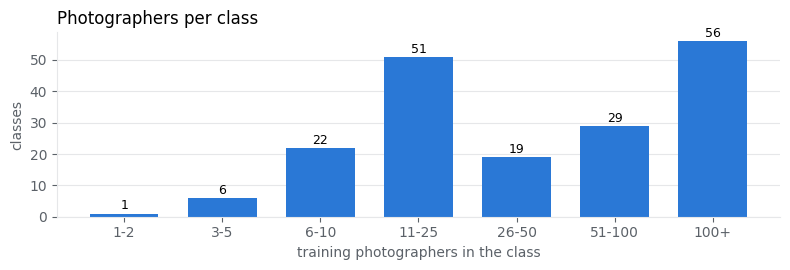


Classes with under 20% of training photos from India: 47; with none: 7


In [5]:
top = {split: meta[meta["split"] == split]["observer_id"].value_counts() for split in SPLITS}
print(pd.DataFrame({split: {"largest photographer %": values.iloc[0] / values.sum() * 100, "top 10 %": values.head(10).sum() / values.sum() * 100} for split, values in top.items()}).round(1).to_string())

test = meta[meta["split"] == "test"]
busiest = test["observer_id"] == top["test"].index[0]
same_rule = train[train["in_india"] & (pd.to_datetime(train["created_at"], utc=True, errors="coerce").dt.year >= 2022)]
print(f"\nBusiest test photographer: {busiest.sum():,} photos, {test[busiest]['species'].nunique()} species, {test[busiest]['portrait'].mean():.1%} portrait")
print(f"Test without them: {test[~busiest]['portrait'].mean():.1%} portrait, {test[~busiest]['listed'].mean():.1%} WHO-listed")
print(f"Training photos under the same India and 2022+ rule: {same_rule['portrait'].mean():.1%} portrait")

per_class = train.groupby("species")["observer_id"].agg(["nunique", "size"])
leader_share = train.groupby(["species", "observer_id"]).size().groupby("species").max() / per_class["size"]
print(f"\nTraining photographers per class: median {per_class['nunique'].median():.0f}; {(per_class['nunique'] <= 5).sum()} classes have 5 or fewer")
print(f"One photographer takes half or more of {(leader_share >= 0.5).sum()} classes; median top share {leader_share.median():.1%}")

bins = pd.cut(per_class["nunique"], [0, 2, 5, 10, 25, 50, 100, np.inf], labels=["1-2", "3-5", "6-10", "11-25", "26-50", "51-100", "100+"])
counts_by_bin = bins.value_counts().sort_index()
print(counts_by_bin.to_string())
figure, axis = plt.subplots(figsize=(8, 2.8))
axis.bar(counts_by_bin.index.astype(str), counts_by_bin, color=BLUE, width=0.7)
for x, value in enumerate(counts_by_bin):
    axis.annotate(f"{value}", (x, value), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
axis.set(xlabel="training photographers in the class", ylabel="classes", title="Photographers per class")
axis.grid(False, axis="x")
finish(figure, "photographers_per_class")

india_by_class = train.groupby("species")["in_india"].mean()
print(f"\nClasses with under 20% of training photos from India: {(india_by_class < 0.2).sum()}; with none: {(india_by_class == 0).sum()}")

## 5. Dangerous species are covered, but test is thin
All 6 Category 1 classes are in tier 1, but 5 of the 10 Category 2 classes are in tier 2, and 3 WHO-listed classes have no test photos. "Not listed" doesn't mean harmless: 29 of the 168 not-listed classes are vipers or elapids. All nine lookalike pairs have test photos on both sides, at least 58.

In [6]:
listed = classes[classes["who_category"].astype(str) != "not_listed"].sort_values(["who_category", "total"], ascending=[True, False])
print(listed[["species", "who_category", "tier", "train", "val", "test", "test_extra"]].to_string(index=False))
print(f"\n{len(listed)} WHO-listed classes, {listed['total'].sum():,} photos; {classes['family'].isin(['Viperidae', 'Elapidae']).sum()} classes are vipers or elapids")
print(pd.DataFrame({split: {"classes with none": (classes[split] == 0).sum(), "median photos": classes.loc[classes[split] > 0, split].median(), "under 5": ((classes[split] > 0) & (classes[split] < 5)).sum()} for split in SPLITS}).to_string())
print("No test or test_extra photos:", classes[classes["test"] + classes["test_extra"] == 0]["species"].tolist())

venomous_family = ["Viperidae", "Elapidae"]
unknown = meta[meta["split"] == "unknown_pool"].drop_duplicates("species")
for name, group in {"tier 1 classes": classes[classes["tier"] == "tier1"], "tier 2 classes": classes[classes["tier"] == "tier2"], "unknown pool species": unknown}.items():
    print(f"{name}: {len(group)}; WHO-listed {(group['who_category'].astype(str) != 'not_listed').sum()}; vipers or elapids {group['family'].isin(venomous_family).sum()}")

LOOKALIKES = [("Naja naja", "Ptyas mucosa"), ("Naja naja", "Fowlea piscator"), ("Bungarus caeruleus", "Lycodon aulicus"), ("Bungarus caeruleus", "Lycodon travancoricus"),
              ("Bungarus caeruleus", "Lycodon fasciolatus"), ("Daboia russelii", "Eryx conicus"), ("Daboia russelii", "Python molurus"), ("Echis carinatus", "Boiga trigonata"),
              ("Craspedocephalus gramineus", "Rhabdophis plumbicolor")]
test_photos = classes.set_index("species")["test"]
print(pd.DataFrame([{"dangerous": a, "lookalike": b, "dangerous test photos": test_photos.get(a, 0), "lookalike test photos": test_photos.get(b, 0)} for a, b in LOOKALIKES]).to_string(index=False))

                     species who_category  tier  train  val  test  test_extra
                   Naja naja            1 tier1   2076  338   324         190
             Echis carinatus            1 tier1   1238  273    64         196
             Daboia russelii            1 tier1   1123  196   170          99
          Bungarus caeruleus            1 tier1    799  177   107          44
             Hypnale hypnale            1 tier1    747  155   124          47
               Naja kaouthia            1 tier1    486  127    22         115
Craspedocephalus malabaricus            2 tier1   1236  279   217          57
  Craspedocephalus gramineus            2 tier1    813  180   298          58
          Bungarus fasciatus            2 tier1    952  140    17         202
       Macrovipera lebetinus            2 tier1    709  115     0         116
          Ophiophagus hannah            2 tier1    448   66    10          75
     Trimeresurus erythrurus            2 tier2    160   38    1

## 6. Many snakes are small in the frame
The median snake spans 63% of the photo's long side, but at a 224 px input 6.9% of snakes are under 64 px, against 2.5% at 320 and 1.5% at 384. We start at 320 and compare sizes in Milestone 3.

Median snake: 63% of the photo's long side
At a 224 px input, 6.9% of snakes are under 64 px
At a 320 px input, 2.5% of snakes are under 64 px
At a 384 px input, 1.5% of snakes are under 64 px


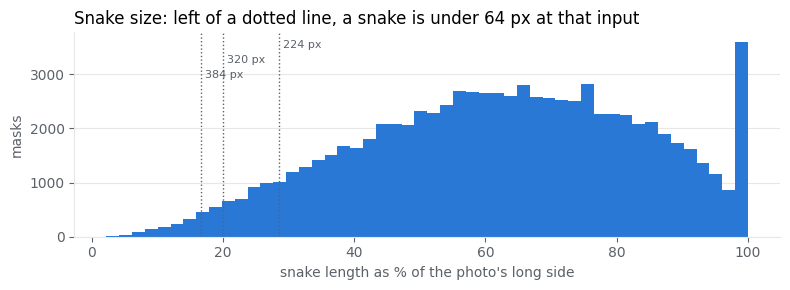

In [7]:
has_mask = masks["n_snake_boxes"].fillna(0) > 0
boxed = masks[has_mask].merge(meta[["path", "width", "height"]], on="path")
longest = boxed["snake_boxes"].map(lambda text: (lambda box: max(box[2] - box[0], box[3] - box[1]))(json.loads(text)[0]))
length = longest / boxed[["width", "height"]].max(axis=1) * 100
print(f"Median snake: {length.median():.0f}% of the photo's long side")
for size in INPUT_SIZES:
    print(f"At a {size} px input, {(length * size / 100 < SMALL_SNAKE_PX).mean():.1%} of snakes are under {SMALL_SNAKE_PX} px")

figure, axis = plt.subplots(figsize=(8, 3))
axis.hist(length, bins=50, color=BLUE)
for row, size in enumerate(INPUT_SIZES):
    axis.axvline(SMALL_SNAKE_PX / size * 100, color=MUTED, linestyle=":", linewidth=1)
    axis.annotate(f"{size} px", (SMALL_SNAKE_PX / size * 100, axis.get_ylim()[1]), xytext=(3, -11 - 11 * row), textcoords="offset points", fontsize=8, color=MUTED)
axis.set(xlabel="snake length as % of the photo's long side", ylabel="masks", title=f"Snake size: left of a dotted line, a snake is under {SMALL_SNAKE_PX} px at that input")
axis.grid(False, axis="x")
finish(figure, "snake_size")

## 7. A quarter of the masks can't be used yet
Of 85,067 training photos, 82,354 have a mask and 63,438 pass our quality rules. The other 21,629 (25.4%) stay out of segmentation training until a hand check. The median mask covers just 6.1% of its photo, so pixel accuracy would flatter a model that predicts all background. We use IoU and Dice.

85,067 training photos: 82,354 masks, 2,713 no snake, 21,629 flagged (25.4%), 63,438 usable; hands cut from 3,891
who_category
1             22.0
2             18.3
not_listed    26.2
Median mask covers 6.1% of its photo, so the rest is background: score masks with IoU and Dice, not pixel accuracy


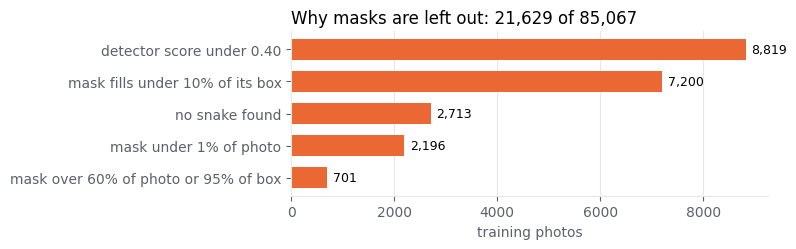

In [8]:
reason = pd.Series("usable", index=masks.index)
flagged = masks["flagged"].astype(bool)
reason[flagged & ((masks["mask_area_fraction"] > 0.60) | (masks["fill_ratio"] > 0.95))] = "mask over 60% of photo or 95% of box"
reason[flagged & (masks["mask_area_fraction"] < 0.01)] = "mask under 1% of photo"
reason[flagged & (masks["fill_ratio"] < 0.10)] = "mask fills under 10% of its box"
reason[flagged & (masks["det_score"] < 0.40)] = "detector score under 0.40"
reason[~has_mask] = "no snake found"
assert (reason[flagged] != "usable").all() and (reason[~flagged] == "usable").all()
counts = reason[reason != "usable"].value_counts().sort_values()
print(f"{len(masks):,} training photos: {has_mask.sum():,} masks, {(~has_mask).sum():,} no snake, {flagged.sum():,} flagged ({flagged.mean():.1%}), {(~flagged).sum():,} usable; hands cut from {(masks['n_removed_boxes'] > 0).sum():,}")
print((masks.groupby(masks["who_category"].astype(str))["flagged"].mean() * 100).round(1).to_string())
print(f"Median mask covers {masks.loc[has_mask, 'mask_area_fraction'].median():.1%} of its photo, so the rest is background: score masks with IoU and Dice, not pixel accuracy")

figure, axis = plt.subplots(figsize=(8, 2.6))
axis.barh(counts.index, counts, color=ORANGE, height=0.65)
label_bars(axis, counts)
axis.set(xlabel="training photos", title=f"Why masks are left out: {counts.sum():,} of {len(masks):,}")
axis.grid(False, axis="y")
finish(figure, "mask_flags")

## 8. Photo size, colour and copies
99.6% of photos have a 500 px long side and 0.7% have a short side under 224 px, so resizing is safe. Average colour is within 0.04 of ImageNet's, so we keep ImageNet normalisation for pretrained encoders. 12.1% of sampled photos are dark enough for exposure correction. No validation or test photo is within 4 bits of a training photo.

In [9]:
longest_side, shortest_side = meta[["width", "height"]].max(axis=1), meta[["width", "height"]].min(axis=1)
print(f"Long side exactly 500 px: {(longest_side == 500).mean():.1%}; short side under 224 px: {(shortest_side < 224).mean():.1%}; median {meta['width'].median():.0f} x {meta['height'].median():.0f}; {meta['bytes'].sum() / 1e9:.1f} GB")
print(f"Taken in India: {meta['in_india'].mean():.1%}; obscured location: {meta['obscured'].astype(bool).mean():.1%}; no coordinates: {meta['latitude'].isna().sum():,}")

sample = train.sample(frac=1, random_state=42).groupby("species").head(COLOUR_PHOTOS_PER_CLASS)
colours = np.array([np.asarray(Image.open(DATA_DIR / "data" / path).convert("RGB"), dtype=np.float32).mean(axis=(0, 1)) for path in sample["path"]])
brightness = colours.mean(axis=1)
print(f"Average photo colour on {len(sample):,} training photos: {(colours.mean(axis=0) / 255).round(3)}; ImageNet {IMAGENET_MEAN}")
print(f"Exposure correction applies to {(brightness < DARK_BELOW).mean():.1%} (dark) and {(brightness > BRIGHT_ABOVE).mean():.1%} (overexposed) of these photos")

popcount = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
to_bits = lambda hashes: np.array([int(value, 16) for value in hashes], dtype=np.uint64)
bank = to_bits(train["phash"])
for split in SPLITS[1:]:
    hashes = to_bits(meta.loc[meta["split"] == split, "phash"])
    closest = np.concatenate([popcount[(hashes[i:i + 1000, None] ^ bank[None, :]).view(np.uint8).reshape(len(hashes[i:i + 1000]), len(bank), 8)].sum(axis=2).min(axis=1) for i in range(0, len(hashes), 1000)])
    print(f"{split:<11} within 4 bits of a training photo: {(closest <= 4).sum()}; within 8 bits: {(closest <= 8).sum()}")

Long side exactly 500 px: 99.6%; short side under 224 px: 0.7%; median 500 x 375; 16.4 GB
Taken in India: 37.8%; obscured location: 17.7%; no coordinates: 763
Average photo colour on 5,260 training photos: [0.455 0.439 0.369]; ImageNet (0.485, 0.456, 0.406)
Exposure correction applies to 12.1% (dark) and 0.2% (overexposed) of these photos
val         within 4 bits of a training photo: 0; within 8 bits: 111
test        within 4 bits of a training photo: 0; within 8 bits: 27
test_extra  within 4 bits of a training photo: 0; within 8 bits: 63
